# Day 02b: Tokenization from First Principles

**Time:** about 45-60 minutes  
**Prerequisites:** basic Python only  
**Goal:** follow text all the way from a visible character to Unicode code points, UTF-8 bytes, BPE token pieces, and token IDs.

This notebook is self-contained. It downloads the two small GPT-2 tokenizer files it needs and does **not** require the Day 02a model notebook.

We will answer one deceptively simple question:

> Why can one visible emoji such as `🏡` become several token IDs?

The complete path is:

```text
visible text
    -> Unicode code points
    -> UTF-8 bytes
    -> tokenizer-specific byte symbols
    -> BPE merge rules
    -> token pieces
    -> token IDs
    -> embedding rows used by the model
```


## Roadmap

We will keep four layers separate:

1. **Unicode** assigns numeric identities called code points to text characters.
2. **UTF-8** encodes those code points as bytes.
3. **A tokenizer** groups byte sequences into reusable token pieces and assigns IDs.
4. **An LLM** learns what those token IDs mean in context.

The tokenizer is deterministic preprocessing. No neural network or backpropagation runs during tokenization.


In [5]:
# Dependencies used by the teaching examples.
# If an import is missing, run this in a new notebook cell:
# %pip install regex matplotlib tiktoken transformers

from collections import Counter, defaultdict
from pathlib import Path
from pprint import pprint
import html
import json
import os
import unicodedata
import urllib.request

import matplotlib.pyplot as plt
import regex  # Unlike Python's re, this supports Unicode categories and grapheme clusters.
from IPython.display import HTML, display

print("Python is ready.")


Python is ready.


## 1. Bits, bytes, and ASCII

At the lowest useful level for this discussion, memory stores **bits**: values that are either `0` or `1`.

Eight bits form one **byte**. A byte can represent 256 values, from 0 through 255.

ASCII was an early agreement that mapped small numbers to characters. For example, decimal `65` represents `A`.


In [6]:
ascii_examples = ["A", "B", "a", "0"]

print(f"{'Character':<10} {'Decimal':>8} {'Hex':>8} {'8-bit binary':>14}")
print("-" * 44)
for character in ascii_examples:
    value = ord(character)
    print(f"{character!r:<10} {value:>8} {value:>8X} {value:>14b}")

print("\nA byte has 8 bits, so it can hold values from 0 to", 2**8 - 1)


Character   Decimal      Hex   8-bit binary
--------------------------------------------
'A'              65       41        1000001
'B'              66       42        1000010
'a'              97       61        1100001
'0'              48       30         110000

A byte has 8 bits, so it can hold values from 0 to 255


ASCII covers English letters, digits, punctuation, and control characters, but it cannot represent writing systems such as Hindi, Bengali, or Chinese, nor modern emoji. We need a global system of character identities. That system is Unicode.


## 2. Unicode: identities, not storage bytes

Unicode assigns a number called a **code point** to textual elements. Code points are conventionally written as `U+` followed by hexadecimal digits.

Examples:

| Text | Code point |
|---|---|
| `A` | `U+0041` |
| `é` | `U+00E9` |
| `中` | `U+4E2D` |
| `क` | `U+0915` |
| `🏡` | `U+1F3E1` |

In Python, `ord(character)` returns the numeric code point, while `chr(number)` performs the reverse mapping.


In [7]:
def inspect_code_points(text):
    """Return one record for each Python Unicode code point in text."""
    records = []
    for index, character in enumerate(text):
        records.append({
            "index": index,
            "character": repr(character),
            "code_point": f"U+{ord(character):04X}",
            "decimal": ord(character),
            "unicode_name": unicodedata.name(character, "<no assigned name>"),
        })
    return records


for row in inspect_code_points("Aé中क🏡"):
    print(row)


{'index': 0, 'character': "'A'", 'code_point': 'U+0041', 'decimal': 65, 'unicode_name': 'LATIN CAPITAL LETTER A'}
{'index': 1, 'character': "'é'", 'code_point': 'U+00E9', 'decimal': 233, 'unicode_name': 'LATIN SMALL LETTER E WITH ACUTE'}
{'index': 2, 'character': "'中'", 'code_point': 'U+4E2D', 'decimal': 20013, 'unicode_name': 'CJK UNIFIED IDEOGRAPH-4E2D'}
{'index': 3, 'character': "'क'", 'code_point': 'U+0915', 'decimal': 2325, 'unicode_name': 'DEVANAGARI LETTER KA'}
{'index': 4, 'character': "'🏡'", 'code_point': 'U+1F3E1', 'decimal': 127969, 'unicode_name': 'HOUSE WITH GARDEN'}


In [8]:
emoji = "🏡"

print("Character:", emoji)
print("Decimal code point:", ord(emoji))
print("Hexadecimal:", hex(ord(emoji)))
print("Unicode notation:", f"U+{ord(emoji):04X}")
print("Round trip with chr():", chr(ord(emoji)))


Character: 🏡
Decimal code point: 127969
Hexadecimal: 0x1f3e1
Unicode notation: U+1F3E1
Round trip with chr(): 🏡


### Visible symbols are not always single code points

What a reader perceives as one symbol is called a **grapheme cluster**. It may contain multiple Unicode code points.

For example, `👩🏽‍💻` combines a base emoji, a skin-tone modifier, a zero-width joiner, and a laptop. Python's `len()` counts code points, not user-perceived grapheme clusters.


In [9]:
visible_examples = ["A", "é", "中", "🏡", "❤️", "🇮🇳", "👩🏽‍💻"]

print(f"{'Text':<10} {'Code points':>12} {'Graphemes':>10} {'UTF-8 bytes':>12}")
print("-" * 50)
for text in visible_examples:
    graphemes = regex.findall(r"\X", text)
    print(f"{text!r:<10} {len(text):>12} {len(graphemes):>10} {len(text.encode('utf-8')):>12}")

complex_emoji = "👩🏽‍💻"
print("\nCode points inside", complex_emoji)
for row in inspect_code_points(complex_emoji):
    print(" ", row["code_point"], row["unicode_name"])


Text        Code points  Graphemes  UTF-8 bytes
--------------------------------------------------
'A'                   1          1            1
'é'                   1          1            2
'中'                   1          1            3
'🏡'                   1          1            4
'❤️'                  2          1            6
'🇮🇳'                  2          1            8
'👩🏽\u200d💻'            4          1           15

Code points inside 👩🏽‍💻
  U+1F469 WOMAN
  U+1F3FD EMOJI MODIFIER FITZPATRICK TYPE-4
  U+200D ZERO WIDTH JOINER
  U+1F4BB PERSONAL COMPUTER


## 3. UTF-8: turning code points into bytes

Unicode says which number identifies a character. It does not, by itself, say which bytes a file or network request should contain.

UTF-8 is a variable-length encoding:

| Code-point range | UTF-8 size |
|---|---:|
| `U+0000`-`U+007F` | 1 byte |
| `U+0080`-`U+07FF` | 2 bytes |
| `U+0800`-`U+FFFF` | 3 bytes |
| `U+10000`-`U+10FFFF` | 4 bytes |

ASCII characters retain their original single-byte values, which makes UTF-8 backward-compatible with ASCII.


In [10]:
def inspect_utf8(text):
    """Print the code points and the exact UTF-8 byte sequence for text."""
    encoded = text.encode("utf-8")
    print("Text:", repr(text))
    print("Python code-point count:", len(text))
    print("Grapheme count:", len(regex.findall(r"\X", text)))
    print("UTF-8 byte count:", len(encoded))
    print("UTF-8 repr:", encoded)
    print("UTF-8 hex:", encoded.hex(" "))
    print()
    print(f"{'Decimal':>8} {'Hex':>6} {'Binary':>10}")
    for byte in encoded:
        print(f"{byte:>8} {byte:>6X} {byte:>010b}")
    return encoded


home_bytes = inspect_utf8("🏡")
assert home_bytes == bytes([0xF0, 0x9F, 0x8F, 0xA1])
assert home_bytes.decode("utf-8") == "🏡"


Text: '🏡'
Python code-point count: 1
Grapheme count: 1
UTF-8 byte count: 4
UTF-8 repr: b'\xf0\x9f\x8f\xa1'
UTF-8 hex: f0 9f 8f a1

 Decimal    Hex     Binary
     240     F0 0011110000
     159     9F 0010011111
     143     8F 0010001111
     161     A1 0010100001


/Users/rounakshow/Developer/inference_engineering/100-days-of-inference/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 127969 (\N{HOUSE WITH GARDEN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


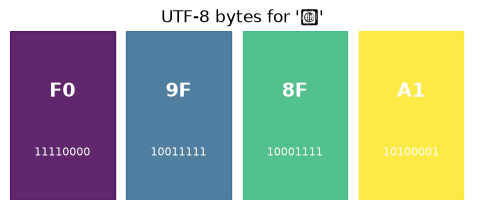

In [11]:
def visualize_utf8_bytes(text):
    """Draw one colored box for every UTF-8 byte in text."""
    encoded = text.encode("utf-8")
    colors = plt.cm.viridis([i / max(1, len(encoded) - 1) for i in range(len(encoded))])
    fig, ax = plt.subplots(figsize=(max(6, len(encoded) * 1.35), 2.2))
    for index, (byte, color) in enumerate(zip(encoded, colors)):
        ax.add_patch(plt.Rectangle((index, 0), 0.9, 1, color=color, alpha=0.85))
        ax.text(index + 0.45, 0.64, f"{byte:02X}", ha="center", va="center", color="white", fontsize=14, weight="bold")
        ax.text(index + 0.45, 0.28, f"{byte:08b}", ha="center", va="center", color="white", fontsize=8)
    ax.set_xlim(0, max(1, len(encoded)))
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.set_title(f"UTF-8 bytes for {text!r}")
    plt.show()


visualize_utf8_bytes("🏡")


## 4. Bytes are not token IDs

The house emoji is one grapheme, one code point, and four UTF-8 bytes:

```text
🏡 -> U+1F3E1 -> F0 9F 8F A1
```

A tokenizer adds another grouping layer. Depending on its learned vocabulary, it might keep all four bytes together, split them into two pieces, or split them into more pieces.

The token IDs are arbitrary row numbers in that tokenizer's vocabulary. They are **not** Unicode code points and they are **not** the byte values.


In [12]:
import tiktoken

o200k = tiktoken.get_encoding("o200k_base")
emoji_text = "🏡"
o200k_ids = o200k.encode(emoji_text)

print("Tokenizer: o200k_base")
print("Text:", emoji_text)
print("Token IDs:", o200k_ids)
print()

for token_id in o200k_ids:
    piece = o200k.decode_single_token_bytes(token_id)
    print(
        f"ID {token_id:>6}: bytes={piece.hex(' '):<12} "
        f"decoded alone={piece.decode('utf-8', errors='replace')!r}"
    )

print("\nReconstructed:", o200k.decode(o200k_ids))
assert o200k.decode(o200k_ids) == emoji_text


Tokenizer: o200k_base
Text: 🏡
Token IDs: [52622, 94]

ID  52622: bytes=f0 9f 8f     decoded alone='�'
ID     94: bytes=a1           decoded alone='�'

Reconstructed: 🏡


Notice the replacement character `�` when a token piece is decoded independently. A partial byte sequence may not be valid UTF-8 by itself. Concatenating all token bytes first reconstructs the original emoji perfectly.

The exact split depends on the selected vocabulary. Later, we will see that GPT-2 tokenizes the same emoji differently from `o200k_base`.


## 5. Why use subword tokens?

There are several possible units:

| Strategy | Advantage | Problem |
|---|---|---|
| Characters/code points | Small conceptual alphabet | Long sequences; grapheme and language complications |
| Raw bytes | Exactly 256 base values; covers any UTF-8 text | Even longer sequences |
| Whole words | Short sequences for known words | Huge vocabulary and unknown-word problems |
| Subwords/BPE | Common chunks stay compact; rare text can be decomposed | Requires a trained, model-specific vocabulary |

BPE chooses a reusable middle ground. Common patterns become single tokens; uncommon text remains representable as smaller pieces.


In [9]:
comparison_text = "Kubernetes café 🏡"

print("Text:", repr(comparison_text))
print("Code points:", list(comparison_text))
print("Code-point count:", len(comparison_text))
print("UTF-8 byte count:", len(comparison_text.encode("utf-8")))
print("Whitespace-split words:", comparison_text.split())
print("o200k token IDs:", o200k.encode(comparison_text))
print("o200k token count:", len(o200k.encode(comparison_text)))


Text: 'Kubernetes café 🏡'
Code points: ['K', 'u', 'b', 'e', 'r', 'n', 'e', 't', 'e', 's', ' ', 'c', 'a', 'f', 'é', ' ', '🏡']
Code-point count: 17
UTF-8 byte count: 21
Whitespace-split words: ['Kubernetes', 'café', '🏡']
o200k token IDs: [42, 57796, 30469, 9552, 237, 94]
o200k token count: 6


## 6. Two different operations: train a tokenizer, then use it

This distinction is essential.

### Tokenizer training (performed once, offline)

```text
training corpus
  -> normalization and pre-tokenization choices
  -> count adjacent symbol pairs
  -> repeatedly merge frequent pairs
  -> frozen vocabulary and ordered merge rules
```

The tokenizer designer chooses the corpus, base alphabet, pre-tokenization behavior, vocabulary target, minimum frequency, special tokens, and tie-breaking policy. The BPE algorithm then counts pairs and learns the merge order. No neural network is involved.

### Tokenizer encoding (performed for every input)

```text
new text
  -> same preprocessing
  -> apply the already-learned merge rules
  -> look up token IDs
```

Encoding does not learn new rules and does not change the vocabulary.


## 7. Train a tiny character-level BPE tokenizer

We will first use characters so the training algorithm is easy to see. Production GPT-2 uses the same pair-counting idea on byte-derived symbols after pre-tokenization.

Our tiny corpus contains repeated forms of `low`:


In [13]:
toy_corpus = ["low", "lower", "lowest", "low", "lower", "low"]
word_freqs = Counter(toy_corpus)
splits = {word: list(word) for word in word_freqs}
base_vocabulary = sorted({symbol for pieces in splits.values() for symbol in pieces})

print("Word frequencies:")
pprint(dict(word_freqs))
print("\nInitial splits:")
pprint(splits)
print("\nBase vocabulary:", base_vocabulary)


Word frequencies:
{'low': 3, 'lower': 2, 'lowest': 1}

Initial splits:
{'low': ['l', 'o', 'w'],
 'lower': ['l', 'o', 'w', 'e', 'r'],
 'lowest': ['l', 'o', 'w', 'e', 's', 't']}

Base vocabulary: ['e', 'l', 'o', 'r', 's', 't', 'w']


In [14]:
def compute_pair_frequencies(splits, word_freqs):
    """Count adjacent pairs, weighted by how often each word occurs."""
    pair_counts = defaultdict(int)
    for word, frequency in word_freqs.items():
        symbols = splits[word]
        for left, right in zip(symbols[:-1], symbols[1:]):
            pair_counts[(left, right)] += frequency
    return dict(pair_counts)


pair_counts = compute_pair_frequencies(splits, word_freqs)
for pair, count in sorted(pair_counts.items(), key=lambda item: (-item[1], item[0])):
    print(f"{pair}: {count}")


('l', 'o'): 6
('o', 'w'): 6
('w', 'e'): 3
('e', 'r'): 2
('e', 's'): 1
('s', 't'): 1


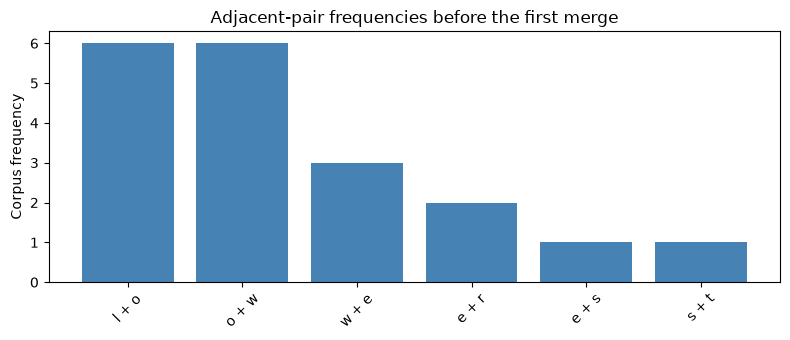

In [15]:
ordered_pairs = sorted(pair_counts.items(), key=lambda item: (-item[1], item[0]))
labels = [" + ".join(pair) for pair, _ in ordered_pairs]
counts = [count for _, count in ordered_pairs]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(labels, counts, color="steelblue")
ax.set_title("Adjacent-pair frequencies before the first merge")
ax.set_ylabel("Corpus frequency")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


Several pairs may have the same frequency. A real tokenizer implementation must use a deterministic tie-breaker. In this teaching implementation, ties are resolved lexicographically so repeated runs produce the same rules.


In [16]:
def merge_pair_in_corpus(splits, pair):
    """Merge every non-overlapping occurrence of pair in every corpus word."""
    left, right = pair
    updated = {}
    for word, symbols in splits.items():
        merged = []
        index = 0
        while index < len(symbols):
            if index + 1 < len(symbols) and symbols[index] == left and symbols[index + 1] == right:
                merged.append(left + right)
                index += 2
            else:
                merged.append(symbols[index])
                index += 1
        updated[word] = merged
    return updated


best_pair = min(pair_counts, key=lambda pair: (-pair_counts[pair], pair))
print("Selected pair:", best_pair, "frequency:", pair_counts[best_pair])
print("Before:", splits)
print("After: ", merge_pair_in_corpus(splits, best_pair))


Selected pair: ('l', 'o') frequency: 6
Before: {'low': ['l', 'o', 'w'], 'lower': ['l', 'o', 'w', 'e', 'r'], 'lowest': ['l', 'o', 'w', 'e', 's', 't']}
After:  {'low': ['lo', 'w'], 'lower': ['lo', 'w', 'e', 'r'], 'lowest': ['lo', 'w', 'e', 's', 't']}


In [17]:
def train_toy_bpe(word_freqs, target_vocab_size, minimum_frequency=2):
    """Learn merge rules until a configured stopping condition is reached."""
    current_splits = {word: list(word) for word in word_freqs}
    vocabulary = {symbol for pieces in current_splits.values() for symbol in pieces}
    merges = []
    history = []
    stop_reason = None

    while len(vocabulary) < target_vocab_size:
        pair_counts = compute_pair_frequencies(current_splits, word_freqs)
        if not pair_counts:
            stop_reason = "no adjacent pairs remain"
            break

        best_pair = min(pair_counts, key=lambda pair: (-pair_counts[pair], pair))
        frequency = pair_counts[best_pair]
        if frequency < minimum_frequency:
            stop_reason = f"best pair frequency {frequency} is below {minimum_frequency}"
            break

        current_splits = merge_pair_in_corpus(current_splits, best_pair)
        new_token = "".join(best_pair)
        vocabulary.add(new_token)
        merges.append(best_pair)
        history.append({
            "step": len(merges),
            "pair": best_pair,
            "frequency": frequency,
            "new_token": new_token,
            "vocab_size": len(vocabulary),
        })

    if stop_reason is None:
        stop_reason = f"target vocabulary size {target_vocab_size} reached"

    return vocabulary, merges, current_splits, history, stop_reason


toy_vocab, toy_merges, final_splits, training_history, stop_reason = train_toy_bpe(
    word_freqs,
    target_vocab_size=len(base_vocabulary) + 5,
)

for event in training_history:
    print(event)
print("\nLearned merge order:", toy_merges)
print("Final corpus splits:")
pprint(final_splits)
print("Stop reason:", stop_reason)


{'step': 1, 'pair': ('l', 'o'), 'frequency': 6, 'new_token': 'lo', 'vocab_size': 8}
{'step': 2, 'pair': ('lo', 'w'), 'frequency': 6, 'new_token': 'low', 'vocab_size': 9}
{'step': 3, 'pair': ('low', 'e'), 'frequency': 3, 'new_token': 'lowe', 'vocab_size': 10}
{'step': 4, 'pair': ('lowe', 'r'), 'frequency': 2, 'new_token': 'lower', 'vocab_size': 11}

Learned merge order: [('l', 'o'), ('lo', 'w'), ('low', 'e'), ('lowe', 'r')]
Final corpus splits:
{'low': ['low'], 'lower': ['lower'], 'lowest': ['lowe', 's', 't']}
Stop reason: best pair frequency 1 is below 2


### What stops tokenizer training?

A tokenizer trainer stops according to a configured policy, commonly:

- the target vocabulary size has been reached;
- the requested number of merges has been learned;
- no adjacent pair reaches the minimum frequency;
- no mergeable pairs remain.

The corpus and configuration therefore help decide which chunks exist in the final vocabulary. Once this process finishes, the merge order is frozen and distributed with the model.


In [15]:
def merge_pair_in_sequence(symbols, pair):
    """Merge every non-overlapping occurrence of pair in one symbol sequence."""
    left, right = pair
    result = []
    index = 0
    while index < len(symbols):
        if index + 1 < len(symbols) and symbols[index] == left and symbols[index + 1] == right:
            result.append(left + right)
            index += 2
        else:
            result.append(symbols[index])
            index += 1
    return result


def apply_learned_merges(text, merges):
    """Tokenize text using an already-learned ordered merge list."""
    symbols = list(text)
    for pair in merges:
        symbols = merge_pair_in_sequence(symbols, pair)
    return symbols


for word in ["low", "lower", "lowest", "slow"]:
    print(f"{word!r:>10} -> {apply_learned_merges(word, toy_merges)}")


     'low' -> ['low']
   'lower' -> ['lower']
  'lowest' -> ['lowe', 's', 't']
    'slow' -> ['s', 'low']


The toy tokenizer cannot properly handle an unseen character unless that character belongs to its base vocabulary. Byte-level BPE solves this by starting with all 256 possible byte values, ensuring that any UTF-8 input can be represented.


## 8. Load GPT-2's frozen byte-level BPE vocabulary

GPT-2 stores two key tokenizer artifacts:

- `vocab.json`: token string to integer ID;
- `merges.txt`: ordered BPE merge rules.

The following cell downloads these small files when necessary, making this notebook independent of Day 02a.


In [19]:
MODEL_DIR = Path("gpt2_weights")
MODEL_DIR.mkdir(exist_ok=True)

BASE_URL = "https://huggingface.co/openai-community/gpt2/resolve/main"
TOKENIZER_FILES = ["vocab.json", "merges.txt"]

for filename in TOKENIZER_FILES:
    destination = MODEL_DIR / filename
    if destination.exists():
        print(f"Already exists: {destination} ({destination.stat().st_size:,} bytes)")
    else:
        print(f"Downloading {filename}...")
        urllib.request.urlretrieve(f"{BASE_URL}/{filename}", destination)
        print(f"Downloaded: {destination} ({destination.stat().st_size:,} bytes)")

print("Tokenizer directory:", MODEL_DIR.resolve())


Already exists: gpt2_weights/vocab.json (1,042,301 bytes)
Already exists: gpt2_weights/merges.txt (456,318 bytes)
Tokenizer directory: /Users/rounakshow/Developer/inference_engineering/100-days-of-inference/day02/gpt2_weights


In [20]:
with (MODEL_DIR / "vocab.json").open(encoding="utf-8") as file:
    vocab = json.load(file)

with (MODEL_DIR / "merges.txt").open(encoding="utf-8") as file:
    merge_lines = file.read().splitlines()

merge_rules = [tuple(line.split()) for line in merge_lines[1:] if line]
id_to_token = {token_id: token for token, token_id in vocab.items()}

print(f"Vocabulary entries: {len(vocab):,}")
print(f"Merge rules: {len(merge_rules):,}")
print("Header:", merge_lines[0])
print("First five merge rules:", merge_rules[:5])
print("Last five merge rules:", merge_rules[-5:])
print("Special token ID:", vocab["<|endoftext|>"])


Vocabulary entries: 50,257
Merge rules: 50,000
Header: #version: 0.2
First five merge rules: [('Ġ', 't'), ('Ġ', 'a'), ('h', 'e'), ('i', 'n'), ('r', 'e')]
Last five merge rules: [('om', 'inated'), ('Ġreg', 'ress'), ('ĠColl', 'ider'), ('Ġinform', 'ants'), ('Ġg', 'azed')]
Special token ID: 50256


GPT-2's 50,257-entry vocabulary consists conceptually of:

```text
256 base byte symbols + 50,000 learned merges + 1 special token
```

`merges.txt` stores priority through order: an earlier rule has a lower rank and is applied before a later competing rule.


## 9. Why GPT-2 maps bytes to unusual Unicode symbols

Some byte values correspond to whitespace or non-printable control characters. GPT-2 maps every byte from `0` to `255` onto a printable Unicode character before applying BPE.

This mapping is internal bookkeeping. For example, GPT-2 maps byte `0x20` (space) to `Ġ`. Unicode itself does **not** define `Ġ` as “the space character.”


In [21]:
def bytes_to_unicode():
    """Return GPT-2's reversible mapping from each byte to a printable symbol."""
    byte_values = list(range(ord("!"), ord("~") + 1))
    byte_values += list(range(ord("¡"), ord("¬") + 1))
    byte_values += list(range(ord("®"), ord("ÿ") + 1))

    code_points = byte_values.copy()
    extra_index = 0
    for byte in range(256):
        if byte not in byte_values:
            byte_values.append(byte)
            code_points.append(256 + extra_index)
            extra_index += 1

    return dict(zip(byte_values, map(chr, code_points)))


byte_encoder = bytes_to_unicode()
byte_decoder = {symbol: byte for byte, symbol in byte_encoder.items()}

for byte in [9, 10, 32, 65, 97, 240, 159, 143, 161]:
    print(f"byte={byte:3} hex={byte:02X} -> GPT-2 symbol={byte_encoder[byte]!r}")

assert len(byte_encoder) == 256
assert all(byte_decoder[byte_encoder[byte]] == byte for byte in range(256))


byte=  9 hex=09 -> GPT-2 symbol='ĉ'
byte= 10 hex=0A -> GPT-2 symbol='Ċ'
byte= 32 hex=20 -> GPT-2 symbol='Ġ'
byte= 65 hex=41 -> GPT-2 symbol='A'
byte= 97 hex=61 -> GPT-2 symbol='a'
byte=240 hex=F0 -> GPT-2 symbol='ð'
byte=159 hex=9F -> GPT-2 symbol='Ł'
byte=143 hex=8F -> GPT-2 symbol='ı'
byte=161 hex=A1 -> GPT-2 symbol='¡'


In [22]:
sample = "hello guys"
sample_bytes = sample.encode("utf-8")
mapped_symbols = [byte_encoder[byte] for byte in sample_bytes]

print("Text:", repr(sample))
print("UTF-8 bytes:", sample_bytes)
print("Byte-to-symbol mapping:")
for byte, symbol in zip(sample_bytes, mapped_symbols):
    print(f"  byte {byte:3} ({byte:02X}) -> {symbol!r}")
print("Initial GPT-2 symbols:", mapped_symbols)


Text: 'hello guys'
UTF-8 bytes: b'hello guys'
Byte-to-symbol mapping:
  byte 104 (68) -> 'h'
  byte 101 (65) -> 'e'
  byte 108 (6C) -> 'l'
  byte 108 (6C) -> 'l'
  byte 111 (6F) -> 'o'
  byte  32 (20) -> 'Ġ'
  byte 103 (67) -> 'g'
  byte 117 (75) -> 'u'
  byte 121 (79) -> 'y'
  byte 115 (73) -> 's'
Initial GPT-2 symbols: ['h', 'e', 'l', 'l', 'o', 'Ġ', 'g', 'u', 'y', 's']


## 10. Pre-tokenization: decide where BPE is allowed to operate

GPT-2 does not run BPE across an entire document as one unbroken symbol stream. It first divides text into chunks such as contractions, word-like spans, numbers, punctuation, and whitespace.

The `regex` package is used because GPT-2's pattern relies on Unicode categories such as letters (`\p{L}`) and numbers (`\p{N}`). BPE merging happens inside each chunk, not across chunk boundaries.


In [20]:
GPT2_PATTERN = regex.compile(
    r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+"""
)

pretokenization_example = "We're testing GPT-2: café, numbers 123, and\nnewlines."
chunks = GPT2_PATTERN.findall(pretokenization_example)

print("Original:", repr(pretokenization_example))
print("Chunks:")
for index, chunk in enumerate(chunks):
    print(f"  {index:>2}: {chunk!r}")

assert "".join(chunks) == pretokenization_example


Original: "We're testing GPT-2: café, numbers 123, and\nnewlines."
Chunks:
   0: 'We'
   1: "'re"
   2: ' testing'
   3: ' GPT'
   4: '-'
   5: '2'
   6: ':'
   7: ' café'
   8: ','
   9: ' numbers'
  10: ' 123'
  11: ','
  12: ' and'
  13: '\n'
  14: 'newlines'
  15: '.'


## 11. Apply GPT-2's frozen merge rules incrementally

Encoding-time BPE does not count corpus frequencies. Those frequencies were used earlier, during tokenizer training.

For one new chunk, the encoder repeatedly:

1. lists its adjacent pairs;
2. keeps pairs present in the frozen merge table;
3. chooses the available pair with the **lowest rank**;
4. merges every non-overlapping occurrence of that pair;
5. repeats.

Encoding stops when only one symbol remains, no adjacent pairs remain, or none of the remaining adjacent pairs exist in the merge table.


In [21]:
bpe_ranks = {pair: rank for rank, pair in enumerate(merge_rules)}


def get_pairs(symbols):
    """Return the set of adjacent symbol pairs."""
    return set(zip(symbols[:-1], symbols[1:]))


def choose_highest_priority_pair(symbols, ranks):
    """Return (pair, rank), or (None, None) when no learned rule applies."""
    candidates = [(ranks[pair], pair) for pair in get_pairs(symbols) if pair in ranks]
    if not candidates:
        return None, None
    rank, pair = min(candidates)
    return pair, rank


print("Pairs in 'hello':", get_pairs(list("hello")))
print("Best learned pair:", choose_highest_priority_pair(list("hello"), bpe_ranks))


Pairs in 'hello': {('l', 'o'), ('h', 'e'), ('l', 'l'), ('e', 'l')}
Best learned pair: (('h', 'e'), 2)


In [22]:
def merge_once(symbols, ranks):
    """Perform one highest-priority BPE merge."""
    pair, rank = choose_highest_priority_pair(symbols, ranks)
    if pair is None:
        return list(symbols), None, None
    return merge_pair_in_sequence(symbols, pair), pair, rank


def bpe_merge(symbols, ranks=bpe_ranks):
    """Apply learned BPE rules until no rule can merge the remaining symbols."""
    current = list(symbols)
    while len(current) > 1:
        updated, pair, _ = merge_once(current, ranks)
        if pair is None:
            break
        current = updated
    return current


hello_merged = bpe_merge(mapped_symbols)
print("Before:", mapped_symbols)
print("After: ", hello_merged)
print("Token IDs:", [vocab[token] for token in hello_merged])
assert hello_merged == ["hello", "Ġguys"]


Before: ['h', 'e', 'l', 'l', 'o', 'Ġ', 'g', 'u', 'y', 's']
After:  ['hello', 'Ġguys']
Token IDs: [31373, 3730]


In [23]:
def trace_chunk_merges(chunk):
    """Return initial symbols, merge events, final symbols, and a stop reason."""
    initial = [byte_encoder[byte] for byte in chunk.encode("utf-8")]
    current = initial.copy()
    events = []

    while len(current) > 1:
        before = current.copy()
        updated, pair, rank = merge_once(current, bpe_ranks)
        if pair is None:
            return initial, events, current, "no remaining pair has a learned merge rule"
        current = updated
        events.append({
            "step": len(events) + 1,
            "pair": pair,
            "rank": rank,
            "before": before,
            "after": current.copy(),
        })

    return initial, events, current, "one symbol remains"


for word in ["Juggling", "Kubernetes"]:
    initial, events, final, reason = trace_chunk_merges(word)
    print(f"\nTracing {word!r}")
    print("Start:", initial)
    for event in events:
        print(
            f"  step {event['step']:>2}: {event['pair']} "
            f"(rank {event['rank']}) -> {event['after']}"
        )
    print("Final pieces:", final)
    print("Token IDs:", [vocab[piece] for piece in final])
    print("Stopped because:", reason)



Tracing 'Juggling'
Start: ['J', 'u', 'g', 'g', 'l', 'i', 'n', 'g']
  step  1: ('i', 'n') (rank 3) -> ['J', 'u', 'g', 'g', 'l', 'in', 'g']
  step  2: ('in', 'g') (rank 22) -> ['J', 'u', 'g', 'g', 'l', 'ing']
  step  3: ('u', 'g') (rank 762) -> ['J', 'ug', 'g', 'l', 'ing']
  step  4: ('l', 'ing') (rank 1103) -> ['J', 'ug', 'g', 'ling']
  step  5: ('ug', 'g') (rank 6581) -> ['J', 'ugg', 'ling']
Final pieces: ['J', 'ugg', 'ling']
Token IDs: [41, 6837, 1359]
Stopped because: no remaining pair has a learned merge rule

Tracing 'Kubernetes'
Start: ['K', 'u', 'b', 'e', 'r', 'n', 'e', 't', 'e', 's']
  step  1: ('e', 'r') (rank 7) -> ['K', 'u', 'b', 'er', 'n', 'e', 't', 'e', 's']
  step  2: ('e', 's') (rank 18) -> ['K', 'u', 'b', 'er', 'n', 'e', 't', 'es']
  step  3: ('e', 't') (rank 60) -> ['K', 'u', 'b', 'er', 'n', 'et', 'es']
  step  4: ('b', 'er') (rank 271) -> ['K', 'u', 'ber', 'n', 'et', 'es']
  step  5: ('n', 'et') (rank 3006) -> ['K', 'u', 'ber', 'net', 'es']
  step  6: ('u', 'ber') (ra

The lower-ranked rule wins even if another available pair looks more intuitive to a human. Encoding follows the frozen order learned during tokenizer training; it does not recalculate what is frequent in the current word.


## 12. Assemble the encoder from small pieces

We already have every layer:

```text
text -> pre-tokenized chunks -> UTF-8 bytes -> GPT-2 symbols -> BPE pieces -> IDs
```


In [24]:
def encode_chunk(chunk):
    """Encode one pre-tokenized chunk into GPT-2 BPE strings."""
    byte_symbols = [byte_encoder[byte] for byte in chunk.encode("utf-8")]
    return bpe_merge(byte_symbols)


def encode(text, show_chunks=False):
    """Encode text into GPT-2 token IDs using our implementation."""
    token_ids = []
    for chunk in GPT2_PATTERN.findall(text):
        pieces = encode_chunk(chunk)
        if show_chunks:
            print(f"chunk={chunk!r:<18} pieces={pieces}")
        token_ids.extend(vocab[piece] for piece in pieces)
    return token_ids


print(encode("The cat sat", show_chunks=True))


chunk='The'              pieces=['The']
chunk=' cat'             pieces=['Ġcat']
chunk=' sat'             pieces=['Ġsat']
[464, 3797, 3332]


In [25]:
test_cases = [
    "The cat sat",
    "Inference engineering makes AI apps fast.",
    "Kubernetes",
    "NVIDIA",
    "192.168.1.76",
    "unhappiness",
    "hello guys",
    "café",
    "🏡",
    "line one\nline two",
]

for text in test_cases:
    token_ids = encode(text)
    token_strings = [id_to_token[token_id] for token_id in token_ids]
    print(f"Text:   {text!r}")
    print(f"IDs:    {token_ids}")
    print(f"Tokens: {token_strings}")
    print(f"Count:  {len(token_ids)}")
    print()


Text:   'The cat sat'
IDs:    [464, 3797, 3332]
Tokens: ['The', 'Ġcat', 'Ġsat']
Count:  3

Text:   'Inference engineering makes AI apps fast.'
IDs:    [818, 4288, 8705, 1838, 9552, 6725, 3049, 13]
Tokens: ['In', 'ference', 'Ġengineering', 'Ġmakes', 'ĠAI', 'Ġapps', 'Ġfast', '.']
Count:  8

Text:   'Kubernetes'
IDs:    [42, 18478, 3262, 274]
Tokens: ['K', 'uber', 'net', 'es']
Count:  4

Text:   'NVIDIA'
IDs:    [38021]
Tokens: ['NVIDIA']
Count:  1

Text:   '192.168.1.76'
IDs:    [17477, 13, 14656, 13, 16, 13, 4304]
Tokens: ['192', '.', '168', '.', '1', '.', '76']
Count:  7

Text:   'unhappiness'
IDs:    [403, 71, 42661]
Tokens: ['un', 'h', 'appiness']
Count:  3

Text:   'hello guys'
IDs:    [31373, 3730]
Tokens: ['hello', 'Ġguys']
Count:  2

Text:   'café'
IDs:    [66, 1878, 2634]
Tokens: ['c', 'af', 'Ã©']
Count:  3

Text:   '🏡'
IDs:    [8582, 237, 94]
Tokens: ['ðŁ', 'ı', '¡']
Count:  3

Text:   'line one\nline two'
IDs:    [1370, 530, 198, 1370, 734]
Tokens: ['line', 'Ġone', 'Ċ', 'line'

## 13. Build the decoder

Decoding reverses the layers:

```text
token IDs
  -> GPT-2 vocabulary strings
  -> concatenate byte symbols
  -> recover byte values
  -> UTF-8 decode
  -> original text
```

Individual tokens do not always contain valid UTF-8. The correct operation is to concatenate all recovered bytes before decoding the complete sequence.


In [26]:
def token_id_to_bytes(token_id):
    """Recover the raw byte sequence represented by one GPT-2 token ID."""
    token_string = id_to_token[token_id]
    return bytes(byte_decoder[symbol] for symbol in token_string)


def decode(token_ids):
    """Decode GPT-2 token IDs back into text."""
    combined_bytes = b"".join(token_id_to_bytes(token_id) for token_id in token_ids)
    return combined_bytes.decode("utf-8")


for text in test_cases:
    token_ids = encode(text)
    reconstructed = decode(token_ids)
    print(f"{text!r} -> {token_ids} -> {reconstructed!r}")
    assert reconstructed == text

print("\nEvery round trip matched.")


'The cat sat' -> [464, 3797, 3332] -> 'The cat sat'
'Inference engineering makes AI apps fast.' -> [818, 4288, 8705, 1838, 9552, 6725, 3049, 13] -> 'Inference engineering makes AI apps fast.'
'Kubernetes' -> [42, 18478, 3262, 274] -> 'Kubernetes'
'NVIDIA' -> [38021] -> 'NVIDIA'
'192.168.1.76' -> [17477, 13, 14656, 13, 16, 13, 4304] -> '192.168.1.76'
'unhappiness' -> [403, 71, 42661] -> 'unhappiness'
'hello guys' -> [31373, 3730] -> 'hello guys'
'café' -> [66, 1878, 2634] -> 'café'
'🏡' -> [8582, 237, 94] -> '🏡'
'line one\nline two' -> [1370, 530, 198, 1370, 734] -> 'line one\nline two'

Every round trip matched.


In [27]:
gpt2_home_ids = encode("🏡")

print("Same visible emoji, different tokenizer vocabularies")
print("o200k_base:", o200k_ids)
for token_id in o200k_ids:
    print(" ", token_id, o200k.decode_single_token_bytes(token_id).hex(" "))

print("\nGPT-2:", gpt2_home_ids)
for token_id in gpt2_home_ids:
    print(" ", token_id, token_id_to_bytes(token_id).hex(" "))

print("\nBoth reconstruct:", o200k.decode(o200k_ids), decode(gpt2_home_ids))


Same visible emoji, different tokenizer vocabularies
o200k_base: [52622, 94]
  52622 f0 9f 8f
  94 a1

GPT-2: [8582, 237, 94]
  8582 f0 9f
  237 8f
  94 a1

Both reconstruct: 🏡 🏡


This comparison is why token IDs should never be interpreted without knowing the tokenizer. The same text can produce different pieces and unrelated IDs under different vocabularies.


## 14. Validate our GPT-2 implementation

For a technical implementation, a round-trip test is necessary but not sufficient: an incorrect tokenizer might encode and decode its own invented representation consistently.

We therefore compare our IDs with Hugging Face's GPT-2 tokenizer constructed from the same local `vocab.json` and `merges.txt` files.


In [28]:
from transformers import GPT2TokenizerFast

reference_tokenizer = GPT2TokenizerFast(
    vocab=str(MODEL_DIR / "vocab.json"),
    merges=str(MODEL_DIR / "merges.txt"),
)

all_match = True
for text in test_cases:
    ours = encode(text)
    reference = reference_tokenizer.encode(text)
    matched = ours == reference
    all_match &= matched
    print(f"{'OK' if matched else 'MISMATCH':<8} {text!r:<48} {ours}")

assert all_match
print("\nOur implementation matches the reference on every test case.")


OK       'The cat sat'                                    [464, 3797, 3332]
OK       'Inference engineering makes AI apps fast.'      [818, 4288, 8705, 1838, 9552, 6725, 3049, 13]
OK       'Kubernetes'                                     [42, 18478, 3262, 274]
OK       'NVIDIA'                                         [38021]
OK       '192.168.1.76'                                   [17477, 13, 14656, 13, 16, 13, 4304]
OK       'unhappiness'                                    [403, 71, 42661]
OK       'hello guys'                                     [31373, 3730]
OK       'café'                                           [66, 1878, 2634]
OK       '🏡'                                              [8582, 237, 94]
OK       'line one\nline two'                             [1370, 530, 198, 1370, 734]

Our implementation matches the reference on every test case.


## 15. Visualize token boundaries

The following helper renders each decoded token piece as a colored box. Whitespace is made visible with `·`, `\n`, and `\t` markers.


In [29]:
TOKEN_COLORS = [
    "#DDEBFF", "#E5F6DF", "#FFF0D6", "#F5E1FF",
    "#FFE1E8", "#DDF6F3", "#FFF7B8", "#E8E8FF",
]


def visible_piece(text):
    return text.replace(" ", "·").replace("\n", "\\n").replace("\t", "\\t")


def show_token_boundaries(text):
    token_ids = encode(text)
    boxes = []
    for index, token_id in enumerate(token_ids):
        piece = token_id_to_bytes(token_id).decode("utf-8", errors="replace")
        boxes.append(
            f'<span style="display:inline-block;margin:3px;padding:7px 9px;'
            f'border:1px solid #888;border-radius:6px;background:{TOKEN_COLORS[index % len(TOKEN_COLORS)]}">'
            f'<strong>{html.escape(visible_piece(piece))}</strong><br>'
            f'<small>ID {token_id}</small></span>'
        )
    display(HTML("".join(boxes)))
    print(f"{len(text)} Python code points, {len(text.encode('utf-8'))} UTF-8 bytes, {len(token_ids)} GPT-2 tokens")


show_token_boundaries("Inference engineering with Kubernetes, café, and 🏡")


50 Python code points, 54 UTF-8 bytes, 15 GPT-2 tokens


## 16. Tokenization and inference performance

Token count affects different inference phases differently:

| Quantity | Primary consequence |
|---|---|
| More prompt tokens | More prefill computation, more attention work, larger KV cache, more context usage |
| More generated tokens | More sequential decode iterations and longer generation time |
| Larger tokenizer vocabulary | Potentially fewer tokens, but larger embedding and output-projection tables |

Input tokens are not “one forward pass each” during prefill. Prompt positions can be processed in parallel within each layer, although the total computation and memory requirements still increase with sequence length.


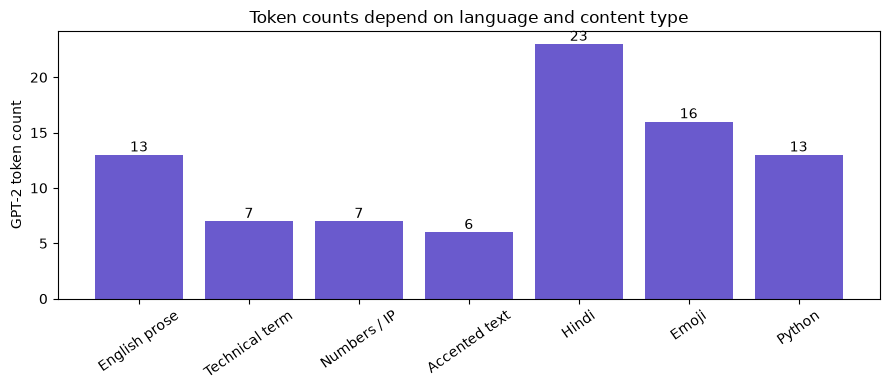

English prose   :  64 code points,  64 bytes,  13 tokens
Technical term  :  22 code points,  22 bytes,   7 tokens
Numbers / IP    :  12 code points,  12 bytes,   7 tokens
Accented text   :  18 code points,  21 bytes,   6 tokens
Hindi           :  13 code points,  37 bytes,  23 tokens
Emoji           :   7 code points,  25 bytes,  16 tokens
Python          :  35 code points,  35 bytes,  13 tokens


In [30]:
efficiency_examples = {
    "English prose": "The model processes a request and generates one token at a time.",
    "Technical term": "Kubernetes autoscaling",
    "Numbers / IP": "192.168.1.76",
    "Accented text": "Un café à Montréal",
    "Hindi": "नमस्ते दुनिया",
    "Emoji": "🏡👩🏽‍💻❤️",
    "Python": "for item in values:\n    print(item)",
}

labels = list(efficiency_examples)
counts = [len(encode(text)) for text in efficiency_examples.values()]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, counts, color="slateblue")
ax.bar_label(bars)
ax.set_ylabel("GPT-2 token count")
ax.set_title("Token counts depend on language and content type")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

for label, text in efficiency_examples.items():
    print(f"{label:<16}: {len(text):>3} code points, {len(text.encode('utf-8')):>3} bytes, {len(encode(text)):>3} tokens")


## Important boundaries of this implementation

- This notebook reproduces GPT-2's byte-level BPE behavior for learning, not for production throughput.
- GPT-2 and `o200k_base` use different vocabularies, so their token IDs and splits differ.
- Other model families may use WordPiece, Unigram, SentencePiece, or different BPE variants.
- Tie-breaking during tokenizer training affects the final vocabulary and must be deterministic.
- Tokenizer artifacts and model weights form a contract: using the wrong tokenizer changes every embedding lookup.
- Unicode code points are not always the same as user-perceived grapheme clusters.


## Key takeaways

1. Unicode assigns character identities; UTF-8 converts those identities into bytes.
2. A visible character may contain several code points, and one code point may require several bytes.
3. BPE training counts frequent adjacent symbols and freezes an ordered merge list.
4. BPE encoding applies those frozen rules; it does not learn new ones.
5. Byte-level BPE begins from all 256 possible bytes, so arbitrary UTF-8 text remains representable.
6. Token IDs are tokenizer-specific vocabulary indices, not code points or byte values.
7. Token count influences prefill work, KV-cache usage, context consumption, and decode length.

The next notebook uses these token IDs to select rows from GPT-2's embedding table, turning discrete integers into 768-dimensional vectors.


## References and further reading

- Hugging Face LLM Course, [Byte-Pair Encoding tokenization](https://huggingface.co/learn/llm-course/en/chapter6/5) - detailed BPE training and implementation walkthrough.
- OpenAI, [Tokenizer](https://platform.openai.com/tokenizer) - interactive token visualization.
- Unicode Consortium, [What is Unicode?](https://home.unicode.org/basic-info/overview/)
- Sennrich, Haddow, and Birch, [Neural Machine Translation of Rare Words with Subword Units](https://aclanthology.org/P16-1162/) (2016).
- GPT-2 tokenizer assets: [`vocab.json`](https://huggingface.co/openai-community/gpt2/blob/main/vocab.json) and [`merges.txt`](https://huggingface.co/openai-community/gpt2/blob/main/merges.txt).
